<a href="https://colab.research.google.com/github/roness3yn/property-investment-intelligence-system/blob/main/AirBNB_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Install Libraries, Mount Google Drive, and Define Dataset Paths

In [2]:
import pandas as pd
import duckdb
from pathlib import Path
from google.colab import drive
!pip install -q duckdb pyarrow
!pip install pyarrow


# Mount Google Drive
drive.mount("/content/drive")

#Define data paths
Listing_Data_Path = "/content/drive/MyDrive/Final Project/Listings/"
Review_Data_Path = "/content/drive/MyDrive/Final Project/Reviews/"
Output_Data_Path = "/content/drive/MyDrive/Final Project/Processed/"

# Create output directory
Path(Output_Data_Path).mkdir(parents=True, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Initialise DuckDB

In [3]:
# Create DuckDB connection
con = duckdb.connect("/content/airbnb_reviews.duckdb")

# Limit memory usage
con.execute("SET memory_limit = '2GB'")

# Limit parallel processing
con.execute("SET threads = 2")

# Allow temporary operations to spill to disk
con.execute("SET temp_directory = '/content/duckdb_temp'")

print("DuckDB connected successfully!")

DuckDB connected successfully!


In [ ]:
#Verify that DuckDB can read the files
reviews_files = sorted(
    Path(Review_Data_Path).glob("*_reviews.csv")
)

print(f"Found {len(reviews_files)} CSV files")

assert len(reviews_files) > 0, "No review files found!"

# Inspect the first file
first_file = str(reviews_files[0])

test_reviews = con.execute("""
    SELECT *
    FROM read_csv_auto(
        ?,
        all_varchar = true
    )
    LIMIT 5
""", [first_file]).df()

display(test_reviews)
print(test_reviews.columns.tolist())

Found 45 CSV files


,listing_id,id,date,reviewer_id,reviewer_name,comments
0,28871,82539,2010-08-22,163752,Dave,Very nice place and people. Great location! ...
1,28871,21518912,2014-10-19,20597737,Zuzana,We were at the double room and I don't have an...
2,28871,26293687,2015-02-09,20543694,Melissa,"Edwin is friendly and humorous guide, his hous..."
3,28871,32450201,2015-05-18,26175845,Franz,"Nos ha gustado mucho el sitio de Edwin, esta i..."
4,28871,32686822,2015-05-20,29217313,Maria,I didn't actually see Edwin because he was out...


['listing_id', 'id', 'date', 'reviewer_id', 'reviewer_name', 'comments']


Creating Dataframes for Listings and Reviews



1. Listings:

In [ ]:
#Dictionary of locations
location_country = {
    "Amsterdam": "Netherlands",
    "Antwerp": "Belgium",
    "Athens": "Greece",
    "Barcelona": "Spain",
    "Bergamo": "Italy",
    "Berlin": "Germany",
    "Bologna": "Italy",
    "Bordeaux": "France",
    "Bristol": "United Kingdom",
    "Brussels": "Belgium",
    "Copenhagen": "Denmark",
    "Crete": "Greece",
    "Dublin": "Ireland",
    "Edinburgh": "United Kingdom",
    "Euskadi": "Spain",
    "Florence": "Italy",
    "Geneva": "Switzerland",
    "Ghent": "Belgium",
    "Girona": "Spain",
    "Greater Manchester": "United Kingdom",
    "Lisbon": "Portugal",
    "London": "United Kingdom",
    "Lyon": "France",
    "Madrid": "Spain",
    "Mallorca": "Spain",
    "Menorca": "Spain",
    "Milan": "Italy",
    "Munich": "Germany",
    "Naples": "Italy",
    "Oslo": "Norway",
    "Paris": "France",
    "Porto": "Portugal",
    "Prague": "Czech Republic",
    "Puglia": "Italy",
    "Riga": "Latvia",
    "Rome": "Italy",
    "Rotterdam": "Netherlands",
    "Sevilla": "Spain",
    "Sicily": "Italy",
    "South Aegean": "Greece",
    "The Hague": "Netherlands",
    "Thessaloniki": "Greece",
    "Valencia": "Spain",
    "Vaud": "Switzerland",
    "Venice": "Italy",
    "Vienna": "Austria"
}


In [ ]:
#Function to combine CSV files to dataframes
def combine_airbnb_files(folder_path, file_type):
    folder = Path(folder_path)
    # Detect files ending with _listings.csv or _reviews.csv
    csv_files = sorted(folder.glob(f"*_{file_type}.csv"))
    print(f"\nFound {len(csv_files)} {file_type} files.")

    if not csv_files:
        raise FileNotFoundError(
            f"No matching CSV files found in {folder}"
        )

    dataframes = []
    file_summary = []

    for file in csv_files:
        # Extract location from filename
        # Example: Greater_Manchester_listings.csv
        # Result: Greater Manchester
        location = (
            file.stem
            .removesuffix(f"_{file_type}")
            .replace("_", " ")
        )
        country = location_country.get(location, "Unknown")

        # Read file
        df = pd.read_csv(
            file,
            low_memory=False
        )

        # Add geographic and source identifiers
        df["location"] = location
        df["country"] = country
        df["source_file"] = file.name

        dataframes.append(df)

        file_summary.append({
            "location": location,
            "country": country,
            "file": file.name,
            "rows": len(df),
            "columns": len(df.columns)
        })

        print(
            f"Loaded {file.name}: "
            f"{len(df):,} rows"
        )

    # Concatenate all files vertically
    master_df = pd.concat(
        dataframes,
        ignore_index=True,
        sort=False
    )

    summary_df = pd.DataFrame(file_summary)

    print(f"\n{file_type.upper()} MASTER CREATED")
    print(f"Total rows: {len(master_df):,}")
    print(f"Total columns: {master_df.shape[1]}")
    print(f"Locations: {master_df['location'].nunique()}")
    print(f"Countries: {master_df['country'].nunique()}")

    return master_df, summary_df

In [ ]:
#Listings master dataframe
listings_master, listings_summary = combine_airbnb_files(
    Listing_Data_Path,
    "listings"
)


Found 45 listings files.
Loaded Amsterdam_listings.csv: 10,369 rows
Loaded Antwerp_listings.csv: 2,535 rows
Loaded Athens_listings.csv: 14,337 rows
Loaded Barcelona_listings.csv: 15,293 rows
Loaded Bergamo_listings.csv: 4,237 rows
Loaded Berlin_listings.csv: 12,776 rows
Loaded Bologna_listings.csv: 4,948 rows
Loaded Bordeaux_listings.csv: 12,217 rows
Loaded Bristol_listings.csv: 3,023 rows
Loaded Brussels_listings.csv: 5,078 rows
Loaded Copenhagen_listings.csv: 23,144 rows
Loaded Crete_listings.csv: 27,333 rows
Loaded Dublin_listings.csv: 6,966 rows
Loaded Edinburgh_listings.csv: 6,244 rows
Loaded Euskadi_listings.csv: 6,248 rows
Loaded Florence_listings.csv: 13,472 rows
Loaded Geneva_listings.csv: 2,593 rows
Loaded Ghent_listings.csv: 1,383 rows
Loaded Girona_listings.csv: 21,257 rows
Loaded Greater_Manchester_listings.csv: 6,930 rows
Loaded Lisbon_listings.csv: 24,876 rows
Loaded London_listings.csv: 92,638 rows
Loaded Lyon_listings.csv: 9,317 rows
Loaded Madrid_listings.csv: 22,708

In [ ]:
#Validate integration
print("\n========== DATA VALIDATION ==========")

# Confirm input row counts were preserved
assert len(listings_master) == listings_summary["rows"].sum()
print("All input rows preserved successfully.")

# Check unmapped locations
print("\nUnmapped listing locations:")
print(
    listings_master.loc[
        listings_master["country"] == "Unknown",
        "location"
    ].unique()
)

# Check duplicate IDs within a location
print("\nDuplicate listing IDs:")
print(
    listings_master.duplicated(
        subset=["location", "id"]
    ).sum()
)

# Check missing values
print("\nTop 15 missing values - Listings:")
display(
    listings_master.isna()
    .sum()
    .sort_values(ascending=False)
    .head(15)
)



========== DATA VALIDATION ==========
All input rows preserved successfully.

Unmapped listing locations:
[]

Duplicate listing IDs:
0

Top 15 missing values - Listings:


,0
neighborhood_overview,756312
host_neighbourhood,756312
host_response_rate,756312
host_acceptance_rate,756312
host_since,756312
host_response_time,756312
host_thumbnail_url,756312
host_verifications,756312
instant_bookable,756312
calendar_updated,756312


In [ ]:
#Display listings summary table
print("\n========== LISTINGS BY LOCATION ==========")
display(
    listings_master.groupby(
        ["country", "location"]
    ).size().reset_index(name="listing_count")
    .sort_values("listing_count", ascending=False)
)



========== LISTINGS BY LOCATION ==========


,country,location,listing_count
44,United Kingdom,London,92638
8,France,Paris,77679
23,Italy,Sicily,56873
21,Italy,Puglia,48683
22,Italy,Rome,37084
13,Greece,South Aegean,36680
12,Greece,Crete,27333
19,Italy,Milan,25750
30,Portugal,Lisbon,24876
5,Denmark,Copenhagen,23144


In [ ]:
#Save master listings dataset
listings_master.to_parquet(
    Path(Output_Data_Path) / "listings_master.parquet",
    index=False
)

# Save a record of source files
listings_summary.to_csv(
    Path(Output_Data_Path) / "listings_file_summary.csv",
    index=False
)

print("\nMaster listings dataset saved successfully!")


Master listings dataset saved successfully!


In [6]:
#Display final listings dataframe

listings_master_path = Path(Output_Data_Path) / "listings_master.parquet"

listings_master = pd.read_parquet(listings_master_path)
print("\nLISTINGS MASTER:")
print(listings_master.shape)
display(listings_master.head())


LISTINGS MASTER:
(756312, 93)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,location,country,source_file
0,28871,https://www.airbnb.com/rooms/28871,20260615212022,2026-06-16,previous scrape,Comfortable double room,Basic bedroom in the center of Amsterdam.,NaN,https://a0.muscache.com/pictures/160889/362340...,124245,...,0363 607B EA74 0BD8 2F6F,NaN,2,0,2,0,4.15,Amsterdam,Netherlands,Amsterdam_listings.csv
1,29051,https://www.airbnb.com/rooms/29051,20260615212022,2026-06-16,previous scrape,Comfortable single / double room,This room can also be rented as a single or a ...,NaN,https://a0.muscache.com/pictures/162009/bd6be2...,124245,...,0363 607B EA74 0BD8 2F6F,NaN,2,0,2,0,4.88,Amsterdam,Netherlands,Amsterdam_listings.csv
2,44129,https://www.airbnb.com/rooms/44129,20260615212022,2026-06-24,previous scrape,Luxury design with canal view,"Welcome to my little gem<br /><br />Cozy, brig...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,187728,...,03635399E87602900F47,NaN,4,3,1,0,0.96,Amsterdam,Netherlands,Amsterdam_listings.csv
3,44391,https://www.airbnb.com/rooms/44391,20260615212022,2026-06-24,previous scrape,Quiet 2-bedroom Amsterdam city centre apartment,Guests greatly appreciate the unique location ...,NaN,https://a0.muscache.com/pictures/97741545/3900...,194779,...,0363 E76E F06A C1DD 172C,NaN,1,1,0,0,0.22,Amsterdam,Netherlands,Amsterdam_listings.csv
4,48373,https://www.airbnb.com/rooms/48373,20260615212022,2026-06-24,previous scrape,Cozy family home in Amsterdam South,Charming modern apartment in the quiet and gre...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,220434,...,0363 4A2B A6AD 0196 F684,NaN,1,1,0,0,0.14,Amsterdam,Netherlands,Amsterdam_listings.csv


2. Reviews:

In [ ]:
#Merge reviews files
output_folder = Path(Output_Data_Path)
output_folder.mkdir(parents=True, exist_ok=True)

reviews_files = sorted(
    Path(Review_Data_Path).glob("*_reviews.csv")
)

print(f"Found {len(reviews_files)} review files")

#Work on Colab's local disk for better performance
db_path = "/content/airbnb_reviews.duckdb"
con = duckdb.connect(db_path)
con.execute("SET memory_limit = '2GB'")
con.execute("SET threads = 2")

# Remove previous table if rerunning this integration
con.execute("DROP TABLE IF EXISTS reviews_master")

Found 45 review files


In [ ]:
#Process and integrate files
for i, file in enumerate(reviews_files, start=1):

    location = (
        file.stem
        .removesuffix("_reviews")
        .replace("_", " ")
    )

    country = location_country.get(location, "Unknown")

    print(
        f"[{i}/{len(reviews_files)}] "
        f"Processing {location}, {country}"
    )

    if i == 1:
        con.execute("""
            CREATE TABLE reviews_master AS
            SELECT
                CAST(id AS VARCHAR) AS id,
                CAST(listing_id AS VARCHAR) AS listing_id,
                TRY_CAST(date AS DATE) AS date,
                CAST(reviewer_id AS VARCHAR) AS reviewer_id,
                reviewer_name,
                comments,
                ? AS location,
                ? AS country,
                ? AS source_file
            FROM read_csv_auto(
                ?,
                all_varchar = true
            )
        """, [location, country, file.name, str(file)])

    else:
        con.execute("""
            INSERT INTO reviews_master
            SELECT
                CAST(id AS VARCHAR),
                CAST(listing_id AS VARCHAR),
                TRY_CAST(date AS DATE),
                CAST(reviewer_id AS VARCHAR),
                reviewer_name,
                comments,
                ? AS location,
                ? AS country,
                ? AS source_file
            FROM read_csv_auto(
                ?,
                all_varchar = true
            )
        """, [location, country, file.name, str(file)])

print("All review files integrated.")

[1/45] Processing Amsterdam, Netherlands


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[2/45] Processing Antwerp, Belgium


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[3/45] Processing Athens, Greece


...

[43/45] Processing Vaud, Switzerland
[44/45] Processing Venice, Italy


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[45/45] Processing Vienna, Austria


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

All review files integrated.


In [ ]:
#Validate reviews integration
reviews_summary = con.execute("""
    SELECT
        country,
        location,
        COUNT(*) AS review_count
    FROM reviews_master
    GROUP BY country, location
    ORDER BY review_count DESC
""").df()

display(reviews_summary)

total_reviews = con.execute("""
    SELECT COUNT(*) FROM reviews_master
""").fetchone()[0]

print(f"Total reviews: {total_reviews:,}")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,country,location,review_count
0,Italy,Rome,2477671
1,France,Paris,2404369
2,United Kingdom,London,2241353
3,Portugal,Lisbon,1886932
4,Spain,Madrid,1419360
5,Italy,Sicily,1301042
6,Italy,Milan,1148401
7,Portugal,Porto,1131143
8,Italy,Florence,1108421
9,Spain,Barcelona,1033523


Total reviews: 30,536,441


In [ ]:
#Export to parquet
output_file = (
    "/content/drive/MyDrive/Final Project/"
    "Processed/reviews_master.parquet"
)

safe_path = output_file.replace("'", "''")

con.execute(f"""
    COPY reviews_master
    TO '{safe_path}'
    (FORMAT PARQUET, COMPRESSION ZSTD)
""")

print(f"Saved to: {output_file}")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved to: /content/drive/MyDrive/Final Project/Processed/reviews_master.parquet


In [ ]:
#Display final reviews dataframe
reviews_master_path = Path(Output_Data_Path) / "reviews_master.parquet"
reviews_master = pd.read_parquet(reviews_master_path)

reviews_aggregated = con.execute("""
    SELECT
        location,
        listing_id,

        COUNT(*) AS total_reviews,

        MIN(date) AS first_review_date,
        MAX(date) AS latest_review_date,

        COUNT(DISTINCT reviewer_id) AS unique_reviewers,

        COUNT(*) FILTER (
            WHERE date >= DATE '2025-01-01'
        ) AS reviews_since_2025

    FROM reviews_master

    GROUP BY location, listing_id
""").df()

display(reviews_aggregated.head())

In [ ]:
reviews_overview = con.execute("""
    SELECT
        COUNT(*) AS total_reviews,
        COUNT(DISTINCT id) AS unique_review_ids,
        COUNT(DISTINCT listing_id) AS unique_listing_ids,
        COUNT(DISTINCT location) AS total_locations,
        COUNT(DISTINCT country) AS total_countries
    FROM reviews_master
""").df()

print("\nReviews overview:")
display(reviews_overview)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


Reviews overview:


,total_reviews,unique_review_ids,unique_listing_ids,total_locations,total_countries
0,30536441,30536209,609621,45,16


In [ ]:
#Check reviews for duplications
duplicate_summary = con.execute("""
    SELECT
        COUNT(*) AS total_reviews,
        COUNT(DISTINCT id) AS unique_review_ids,
        COUNT(*) - COUNT(DISTINCT id) AS duplicate_id_count
    FROM reviews_master
""").df()

print("\nDuplicate review IDs:")
display(duplicate_summary)

#Check for duplicated reviews
duplicate_reviews = con.execute("""
    SELECT
        id,
        COUNT(*) AS occurrences,
        COUNT(DISTINCT location) AS locations
    FROM reviews_master
    WHERE id IS NOT NULL
    GROUP BY id
    HAVING COUNT(*) > 1
    ORDER BY occurrences DESC
    LIMIT 20
""").df()

print("\nDuplicate reviews:")
display(duplicate_reviews)

#Check for location duplicates
location_duplicates = con.execute("""
    SELECT
        location,
        id,
        COUNT(*) AS occurrences
    FROM reviews_master
    WHERE id IS NOT NULL
    GROUP BY location, id
    HAVING COUNT(*) > 1
    ORDER BY occurrences DESC
    LIMIT 20
""").df()

print("\nLocation duplicates:")
display(location_duplicates)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


Duplicate review IDs:


,total_reviews,unique_review_ids,duplicate_id_count
0,30536441,30536209,232


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


Duplicate reviews:


,id,occurrences,locations
0,1319457178882457472,2,1
1,1461490768774334118,2,1
2,1511530340829750559,2,1
3,1314402139317904905,2,1
4,1195525039049403436,2,1
5,1641269737966015851,2,1
6,1231061822860824721,2,1
7,1549298531137870856,2,1
8,1529682593918654098,2,1
9,1623144620431549848,2,1


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


Location duplicates:


,location,id,occurrences
0,Milan,1339081349859090000,2
1,Milan,1590537114098816560,2
2,Milan,1207177297153284946,2
3,Milan,1284670791216877933,2
4,Milan,1446374193701291130,2
5,Milan,1598596704278672023,2
6,Milan,1464435035544359189,2
7,Milan,1453562281183995120,2
8,Milan,1441970552994023566,2
9,Milan,1538422012861238577,2


In [ ]:
#Check that duplicate IDs have matching content
duplicate_examples = con.execute("""
    SELECT *
    FROM reviews_master
    WHERE id IN (
        SELECT id
        FROM reviews_master
        WHERE id IS NOT NULL
        GROUP BY id
        HAVING COUNT(*) > 1
    )
    ORDER BY id, location
    LIMIT 30
""").df()

print("\nDuplicate examples:")
display(duplicate_examples)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


Duplicate examples:


,id,listing_id,date,reviewer_id,reviewer_name,comments,location,country,source_file
0,1028170374965039682,1673252920494715673,2023-11-19,155820072,Gabriela,The place met our expectations. We had a nice ...,Milan,Italy,Milan_reviews.csv
1,1028170374965039682,1676881109321435902,2023-11-19,155820072,Gabriela,The place met our expectations. We had a nice ...,Milan,Italy,Milan_reviews.csv
2,1033228750572502330,1673252920494715673,2023-11-26,64959729,Alex,Great place to stay right in Navigli!,Milan,Italy,Milan_reviews.csv
3,1033228750572502330,1676881109321435902,2023-11-26,64959729,Alex,Great place to stay right in Navigli!,Milan,Italy,Milan_reviews.csv
4,1058611246799787043,1676881109321435902,2023-12-31,84475341,Aissa,We spent two nights in this apartment. Everyth...,Milan,Italy,Milan_reviews.csv
5,1058611246799787043,1673252920494715673,2023-12-31,84475341,Aissa,We spent two nights in this apartment. Everyth...,Milan,Italy,Milan_reviews.csv
6,1062908603823073205,1676881109321435902,2024-01-06,295367391,Lidija,"The appartment is new, extremly clean, spaciou...",Milan,Italy,Milan_reviews.csv
7,1062908603823073205,1673252920494715673,2024-01-06,295367391,Lidija,"The appartment is new, extremly clean, spaciou...",Milan,Italy,Milan_reviews.csv
8,1074492532780595244,1673252920494715673,2024-01-22,456634942,Dave,Great apartment in our favourite part of Milan...,Milan,Italy,Milan_reviews.csv
9,1074492532780595244,1676881109321435902,2024-01-22,456634942,Dave,Great apartment in our favourite part of Milan...,Milan,Italy,Milan_reviews.csv


In [ ]:
#Check reviews for missing values
missing_values = con.execute("""
    SELECT
        COUNT(*) AS total_rows,

        COUNT(*) FILTER (WHERE id IS NULL)
            AS missing_review_id,

        COUNT(*) FILTER (WHERE listing_id IS NULL)
            AS missing_listing_id,

        COUNT(*) FILTER (WHERE date IS NULL)
            AS missing_date,

        COUNT(*) FILTER (WHERE reviewer_id IS NULL)
            AS missing_reviewer_id,

        COUNT(*) FILTER (WHERE reviewer_name IS NULL)
            AS missing_reviewer_name,

        COUNT(*) FILTER (WHERE comments IS NULL)
            AS missing_comments,

        COUNT(*) FILTER (WHERE location IS NULL)
            AS missing_location,

        COUNT(*) FILTER (WHERE country IS NULL)
            AS missing_country,

        COUNT(*) FILTER (WHERE source_file IS NULL)
            AS missing_source_file

    FROM reviews_master
""").df()

print("\nMissing values:")
display(missing_values.T)

columns = [
    row[1]
    for row in con.execute(
        "PRAGMA table_info('reviews_master')"
    ).fetchall()
]

missing_queries = []

for col in columns:
    safe_col = '"' + col.replace('"', '""') + '"'

    missing_queries.append(f"""
        SELECT
            '{col.replace("'", "''")}' AS column_name,
            COUNT(*) FILTER (
                WHERE {safe_col} IS NULL
            ) AS missing_count,
            ROUND(
                100.0 * COUNT(*) FILTER (
                    WHERE {safe_col} IS NULL
                ) / NULLIF(COUNT(*), 0),
                2
            ) AS missing_percentage
        FROM reviews_master
    """)

missing_sql = "\nUNION ALL\n".join(missing_queries)

missing_summary = con.execute(f"""
    SELECT *
    FROM ({missing_sql})
    ORDER BY missing_percentage DESC
""").df()

print("\nMissing values by column:")
display(missing_summary)

#Check missing values by location
missing_by_location = con.execute("""
    SELECT
        country,
        location,
        COUNT(*) AS total_reviews,

        COUNT(*) FILTER (
            WHERE comments IS NULL
        ) AS missing_comments,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE comments IS NULL
            ) / NULLIF(COUNT(*), 0),
            2
        ) AS missing_comments_pct,

        COUNT(*) FILTER (
            WHERE date IS NULL
        ) AS missing_dates

    FROM reviews_master
    GROUP BY country, location
    ORDER BY missing_comments_pct DESC
""").df()

print("\nMissing comments by location:")
display(missing_by_location)

#Check for empty strings
empty_comments = con.execute("""
    SELECT
        COUNT(*) AS total_reviews,

        COUNT(*) FILTER (
            WHERE comments IS NULL
        ) AS null_comments,

        COUNT(*) FILTER (
            WHERE comments IS NOT NULL
            AND TRIM(comments) = ''
        ) AS empty_comments,

        COUNT(*) FILTER (
            WHERE comments IS NOT NULL
            AND TRIM(comments) <> ''
        ) AS non_empty_comments

    FROM reviews_master
""").df()

print("\nEmpty comments:")
display(empty_comments)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


Missing values:


,0
total_rows,30536441
missing_review_id,0
missing_listing_id,0
missing_date,0
missing_reviewer_id,0
missing_reviewer_name,31
missing_comments,0
missing_location,0
missing_country,0
missing_source_file,0


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


Missing values by column:


...


Missing comments by location:


,country,location,total_reviews,missing_comments,missing_comments_pct,missing_dates
0,Greece,Athens,917785,0,0.0,0
1,Italy,Bergamo,157148,0,0.0,0
2,Germany,Berlin,680543,0,0.0,0
3,France,Bordeaux,503447,0,0.0,0
4,United Kingdom,Bristol,165838,0,0.0,0
5,Belgium,Brussels,331422,0,0.0,0
6,Ireland,Dublin,368429,0,0.0,0
7,United Kingdom,Edinburgh,676263,0,0.0,0
8,Spain,Euskadi,403056,0,0.0,0
9,Italy,Florence,1108421,0,0.0,0


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


Empty comments:


,total_reviews,null_comments,empty_comments,non_empty_comments
0,30536441,0,1,30536440


In [ ]:
#Save preprocessing files
from pathlib import Path

eda_folder = Path(
    "/content/drive/MyDrive/Final Project/EDA/"
)

eda_folder.mkdir(parents=True, exist_ok=True)

missing_summary.to_csv(
    eda_folder / "reviews_missing_values.csv",
    index=False
)

duplicate_summary.to_csv(
    eda_folder / "reviews_duplicate_summary.csv",
    index=False
)

missing_by_location.to_csv(
    eda_folder / "reviews_missing_by_location.csv",
    index=False
)

print("Review data-quality summaries saved.")

Review data-quality summaries saved.


In [ ]:
#Remove duplicated reviews
con.execute("""
    CREATE OR REPLACE TEMP TABLE duplicate_ids AS
    SELECT id
    FROM reviews_master
    GROUP BY id
    HAVING COUNT(*) > 1
""")

display(con.execute("""
    SELECT COUNT(*) AS duplicated_id_groups
    FROM duplicate_ids
""").df())

con.execute("""
    CREATE OR REPLACE TEMP TABLE reviews_to_keep AS
    SELECT * EXCLUDE (row_num)
    FROM (
        SELECT
            r.*,
            ROW_NUMBER() OVER (
                PARTITION BY r.id
                ORDER BY
                    r.location,
                    r.listing_id,
                    r.source_file
            ) AS row_num
        FROM reviews_master r
        INNER JOIN duplicate_ids d
            ON r.id = d.id
    )
    WHERE row_num = 1
""")

output_folder = Path(
    "/content/drive/MyDrive/Final Project/Processed/"
)

output_folder.mkdir(parents=True, exist_ok=True)

output_file = output_folder / "reviews_clean.parquet"

# Escape the file path for SQL
safe_path = str(output_file).replace("'", "''")

# Export cleaned reviews directly to Google Drive
con.execute(f"""
    COPY (
        SELECT r.*
        FROM reviews_master r
        WHERE NOT EXISTS (
            SELECT 1
            FROM duplicate_ids d
            WHERE d.id = r.id
        )

        UNION ALL BY NAME

        SELECT *
        FROM reviews_to_keep
    )
    TO '{safe_path}'
    (FORMAT PARQUET, COMPRESSION ZSTD)
""")

print(f"Cleaned reviews saved to: {output_file}")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,duplicated_id_groups
0,232


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Cleaned reviews saved to: /content/drive/MyDrive/Final Project/Processed/reviews_clean.parquet


In [ ]:
#Check duplicate removal success
# Check total rows in the saved Parquet file
cleaned_count = con.execute("""
    SELECT COUNT(*)
    FROM read_parquet(?)
""", [str(output_file)]).fetchone()[0]

original_count = con.execute("""
    SELECT COUNT(*)
    FROM reviews_master
""").fetchone()[0]

print(f"Original reviews: {original_count:,}")
print(f"Cleaned reviews: {cleaned_count:,}")
print(f"Duplicates removed: {original_count - cleaned_count:,}")

assert original_count - cleaned_count == 232

Original reviews: 30,536,441
Cleaned reviews: 30,536,209
Duplicates removed: 232


Visualisations and EDA

1. Review data

In [1]:
listings_master = con.execute("""
    SELECT *
    FROM read_parquet(
        '/content/drive/MyDrive/Final Project/'
        'Processed/listings_master.parquet'
    )
""").df()


#average review_scores_rating
highest_average_review_score = (
    listings_master
    .groupby("location")["review_scores_rating"]
    .median()
    .nlargest(10)
    .sort_values()
)

print("median highest reviews")
display(highest_average_review_score)

lowest_average_review_score = (
    listings_master
    .groupby("location")["review_scores_rating"]
    .median()
    .nsmallest(10)
)

print("median lowest reviews")
display(lowest_average_review_score)


NameError: name 'con' is not defined

In [ ]:
#Review frequency per location by season
reviews_by_location_season = con.execute("""
    WITH seasonal_reviews AS (
        SELECT
            country,
            location,
            CASE
                WHEN MONTH(date) IN (12, 1, 2) THEN 'Winter'
                WHEN MONTH(date) IN (3, 4, 5) THEN 'Spring'
                WHEN MONTH(date) IN (6, 7, 8) THEN 'Summer'
                WHEN MONTH(date) IN (9, 10, 11) THEN 'Autumn'
            END AS season,

            CASE
                WHEN MONTH(date) = 12 THEN YEAR(date) + 1
                ELSE YEAR(date)
            END AS season_year

        FROM reviews_clean
        WHERE date IS NOT NULL
    )

    SELECT
        country,
        location,
        season_year,
        season,
        COUNT(*) AS total_reviews

    FROM seasonal_reviews

    GROUP BY
        country,
        location,
        season_year,
        season

    ORDER BY
        country,
        location,
        season_year,
        season
""").df()

display(reviews_by_location_season.head(20))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,country,location,season_year,season,total_reviews
0,Austria,Vienna,2010,Autumn,1
1,Austria,Vienna,2010,Summer,1
2,Austria,Vienna,2011,Autumn,64
3,Austria,Vienna,2011,Spring,5
4,Austria,Vienna,2011,Summer,19
5,Austria,Vienna,2011,Winter,1
6,Austria,Vienna,2012,Autumn,188
7,Austria,Vienna,2012,Spring,148
8,Austria,Vienna,2012,Summer,179
9,Austria,Vienna,2012,Winter,78


In [ ]:
#Seasonal review count
reviews_by_season = con.execute("""
    WITH seasonal_reviews AS (
        SELECT
            date,
            CASE
                WHEN MONTH(date) IN (12, 1, 2) THEN 'Winter'
                WHEN MONTH(date) IN (3, 4, 5) THEN 'Spring'
                WHEN MONTH(date) IN (6, 7, 8) THEN 'Summer'
                WHEN MONTH(date) IN (9, 10, 11) THEN 'Autumn'
            END AS season,

            CASE
                WHEN MONTH(date) = 12 THEN YEAR(date) + 1
                ELSE YEAR(date)
            END AS season_year

        FROM reviews_clean
        WHERE date IS NOT NULL
    )

    SELECT
        season_year,
        season,
        COUNT(*) AS total_reviews

    FROM seasonal_reviews

    GROUP BY season_year, season

    ORDER BY
        season_year,
        CASE season
            WHEN 'Winter' THEN 1
            WHEN 'Spring' THEN 2
            WHEN 'Summer' THEN 3
            WHEN 'Autumn' THEN 4
        END
""").df()

display(reviews_by_season)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,season_year,season,total_reviews
0,2009,Summer,2
1,2009,Autumn,1
2,2010,Winter,3
3,2010,Spring,23
4,2010,Summer,100
...,...,...,...
64,2025,Summer,2038161
65,2025,Autumn,1789701
66,2026,Winter,1116859
67,2026,Spring,1919278


In [ ]:
#Percentage of reviews per season
seasonal_share = reviews_by_location_season.copy()

seasonal_share["annual_reviews"] = (
    seasonal_share.groupby(
        ["location", "season_year"]
    )["total_reviews"].transform("sum")
)

seasonal_share["season_pct"] = (
    seasonal_share["total_reviews"]
    / seasonal_share["annual_reviews"]
    * 100
).round(2)

display(seasonal_share.head(20))

,country,location,season_year,season,total_reviews,annual_reviews,season_pct
0,Austria,Vienna,2010,Autumn,1,2,50.00
1,Austria,Vienna,2010,Summer,1,2,50.00
2,Austria,Vienna,2011,Autumn,64,89,71.91
3,Austria,Vienna,2011,Spring,5,89,5.62
4,Austria,Vienna,2011,Summer,19,89,21.35
5,Austria,Vienna,2011,Winter,1,89,1.12
6,Austria,Vienna,2012,Autumn,188,593,31.70
7,Austria,Vienna,2012,Spring,148,593,24.96
8,Austria,Vienna,2012,Summer,179,593,30.19
9,Austria,Vienna,2012,Winter,78,593,13.15


In [ ]:
#reviews by location
#connect reviews_clean
reviews_path = (
    "/content/drive/MyDrive/Final Project/"
    "Processed/reviews_clean.parquet"
)

safe_path = reviews_path.replace("'", "''")

con.execute(f"""
    CREATE OR REPLACE VIEW reviews_clean AS
    SELECT *
    FROM read_parquet('{safe_path}')
""")


reviews_location_summary = con.execute("""
    SELECT
        country,
        location,
        COUNT(*) AS total_reviews,
        COUNT(DISTINCT listing_id) AS reviewed_listings,
        MIN(date) AS earliest_review,
        MAX(date) AS latest_review
    FROM reviews_clean
    GROUP BY country, location
    ORDER BY total_reviews DESC
""").df()

display(reviews_location_summary)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,country,location,total_reviews,reviewed_listings,earliest_review,latest_review
0,Italy,Rome,2477671,32827,2010-05-14,2026-07-06
1,France,Paris,2404369,61781,2010-01-26,2026-06-28
2,United Kingdom,London,2241353,70832,2009-12-21,2026-06-30
3,Portugal,Lisbon,1886932,21794,2010-07-24,2026-07-02
4,Spain,Madrid,1419360,19105,2010-07-06,2026-07-01
5,Italy,Sicily,1301042,40373,2009-08-26,2026-07-02
6,Italy,Milan,1148169,21941,2010-12-20,2026-07-02
7,Portugal,Porto,1131143,13683,2011-05-10,2026-07-02
8,Italy,Florence,1108421,12216,2010-06-17,2026-07-02
9,Spain,Barcelona,1033523,11822,2010-10-03,2026-07-02


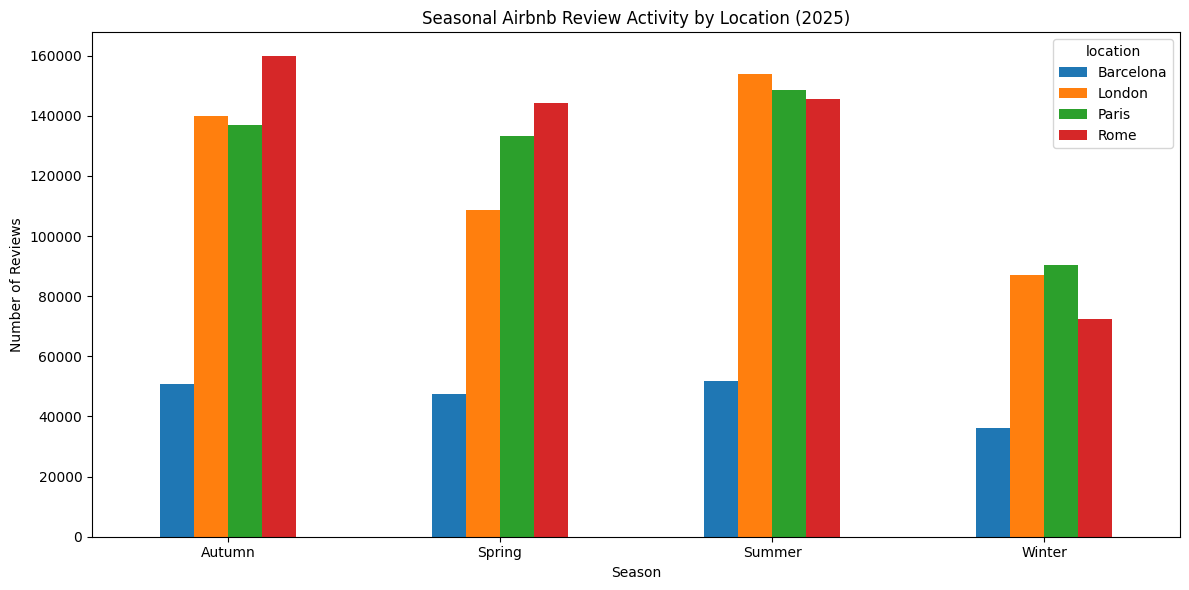

In [ ]:
#Comparison of popular locations

locations = ["Barcelona", "London", "Paris", "Rome"]

# Select the most recent complete calendar year
analysis_year = 2025

plot_data = reviews_by_location_season[
    (reviews_by_location_season["location"].isin(locations)) &
    (reviews_by_location_season["season_year"] == analysis_year)
]

pivot_data = plot_data.pivot(
    index="season",
    columns="location",
    values="total_reviews"
)

pivot_data.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(f"Seasonal Airbnb Review Activity by Location ({analysis_year})")
plt.xlabel("Season")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

2. Host Data

In [ ]:
#Number of hosts and properties by location
host_summary = (
    listings_master
    .groupby("location")
    .agg(
        total_hosts=("host_id", "nunique"),
        total_properties=("id", "nunique")
    )
    .sort_values("total_hosts", ascending=False)
)

display (host_summary)

,total_hosts,total_properties
location,,
Paris,55059,77679
London,52125,92638
Sicily,29047,56873
Puglia,22204,48683
Copenhagen,21094,23144
Rome,19781,37084
South Aegean,15075,36680
Milan,11745,25750
Oslo,11692,13391


In [ ]:
#Median properties per host by country
host_property_count = (
    listings_master
    .groupby("country")["calculated_host_listings_count"]
    .median()
    .sort_values()
)

print("Median Properties per Host by Country")
display(host_property_count)

Median Properties per Host by Country


,calculated_host_listings_count
country,
Denmark,1.0
France,1.0
Germany,1.0
Norway,1.0
Netherlands,1.0
Switzerland,1.0
Ireland,2.0
Belgium,2.0
United Kingdom,2.0


Text(0, 0.5, 'Percentage')

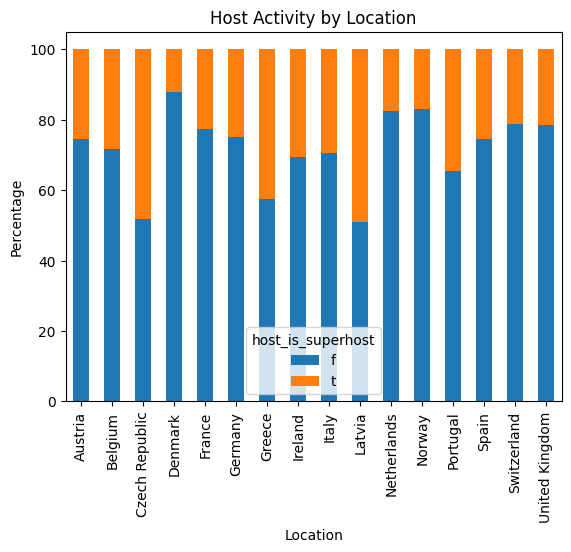

In [ ]:
#host activity by location
host_activity = (
    listings_master
    .groupby("country")["host_is_superhost"]
    .value_counts(normalize=True)
    .unstack(fill_value=0)
    .mul(100)
    .round(2)
)

host_activity.plot(kind="bar", stacked=True)

plt.title("Host Activity by Location")
plt.xlabel("Location")
plt.ylabel("Percentage")

3. Location Data

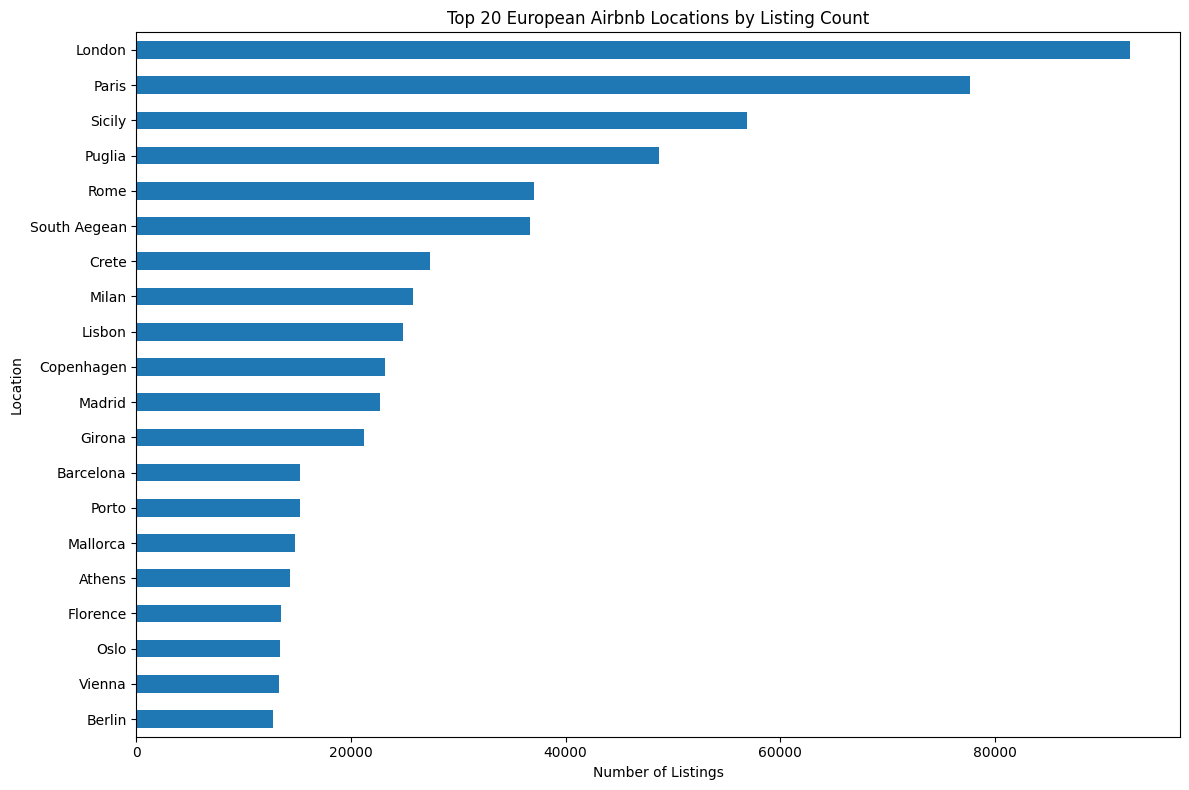

In [ ]:
#Plot of top locations by listing count
import matplotlib.pyplot as plt

location_counts = (
    listings_master["location"]
    .value_counts()
    .head(20)
    .sort_values()
)

plt.figure(figsize=(12, 8))
location_counts.plot(kind="barh")

plt.title("Top 20 European Airbnb Locations by Listing Count")
plt.xlabel("Number of Listings")
plt.ylabel("Location")
plt.tight_layout()
plt.show()

In [ ]:
#display of room types
display(
    listings_master["room_type"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

,proportion
room_type,
Entire home/apt,79.99
Private room,19.31
Hotel room,0.43
Shared room,0.26


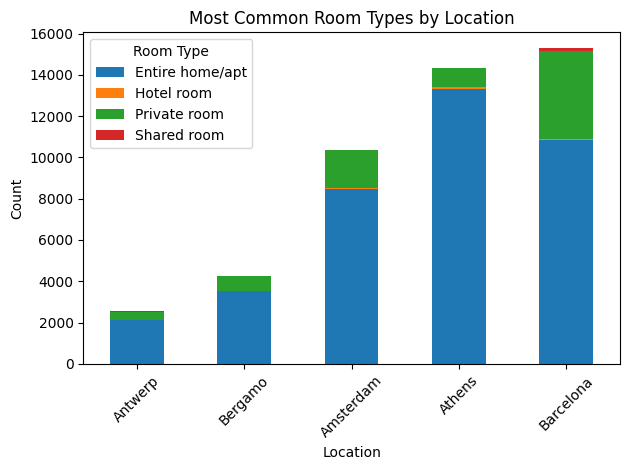

In [ ]:
#Chart of most common room type by location
room_type_counts = (
    listings_master
    .groupby("location")["room_type"]
    .value_counts()
    .head(20)
    .sort_values()
    .unstack(fill_value=0)
)

room_type_counts.plot(kind="bar", stacked=True)

plt.title("Most Common Room Types by Location")
plt.xlabel("Location")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.legend(title="Room Type")
plt.tight_layout()
plt.show()

4. Price Data

In [ ]:
#price summary
price_summary = (
    listings_master["price"]
    .describe()
    .to_frame()
    .T
    .round(2)
)

display(price_summary)

#check all have $ prefix
assert all(listings_master["price"].str.startswith("$"))
print("All prices have $ prefix.")

,count,unique,top,freq
price,610695,55014,$120.00,3515


All prices have $ prefix.


,price_quote_price_per_night
location,
Valencia,150.64
Rotterdam,160.00
Rome,161.67
Florence,166.00
Barcelona,177.67
London,180.00
Dublin,182.64
Euskadi,196.00
Venice,202.46


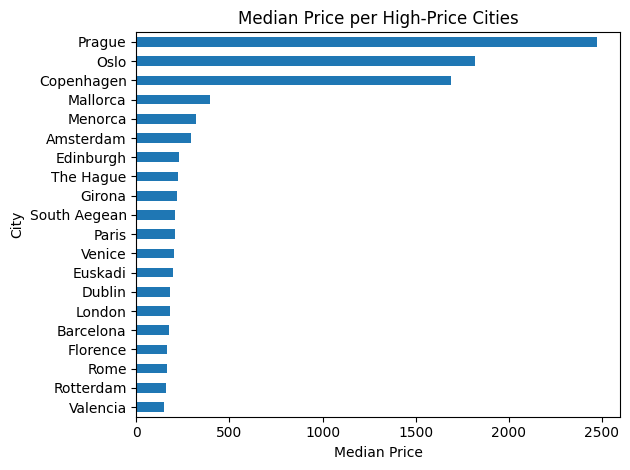

,price_quote_price_per_night
location,
Geneva,0.140
Vaud,0.150
Thessaloniki,75.500
Riga,82.000
Lyon,103.680
Athens,105.000
Naples,107.270
Bordeaux,107.790
Greater Manchester,116.000


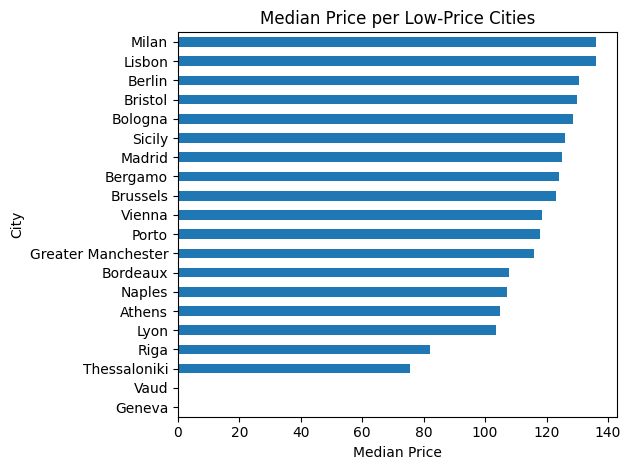

In [ ]:
#median prices in highest priced cities
median_prices_high = (
    listings_master
    .groupby("location")["price_quote_price_per_night"]
    .median()
    .nlargest(20)
    .sort_values()
)

display(median_prices_high)

#Bar chart for high-priced cities
median_prices_high.plot(kind="barh")

plt.title("Median Price per High-Price Cities")
plt.xlabel("Median Price")
plt.ylabel("City")
plt.tight_layout()
plt.show()

#Median prices per lowest price city
median_prices_low = (
    listings_master
    .groupby("location")["price_quote_price_per_night"]
    .median()
    .nsmallest(20)
    .sort_values()
)

display(median_prices_low)

median_prices_low.plot(kind="barh")

plt.title("Median Price per Low-Price Cities")
plt.xlabel("Median Price")
plt.ylabel("City")
plt.tight_layout()
plt.show()

In [ ]:
#yearly availability by country
availability_by_country = (
    listings_master
    .groupby("country")["availability_365"]
    .median()
    .sort_values()
)

print("Median Yearly Availability by Country")
display(availability_by_country)



Median Yearly Availability by Country


,availability_365
country,
Denmark,16.0
Netherlands,36.0
Norway,80.0
France,89.0
Germany,107.0
Ireland,112.0
United Kingdom,143.0
Switzerland,148.0
Greece,180.0


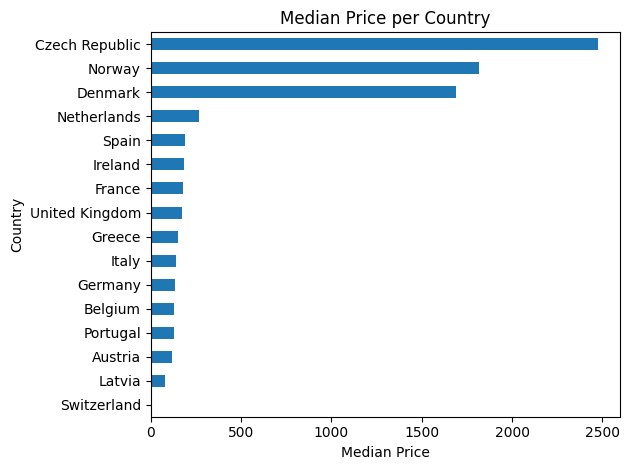

In [ ]:
#graph of median price per country
median_price_by_country = (
    listings_master
    .groupby("country")["price_quote_price_per_night"]
    .median()
    .sort_values()
)

median_price_by_country.plot(kind="barh")

plt.title("Median Price per Country")
plt.xlabel("Median Price")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

5. Geographic Data

In [ ]:
#Geographic data
geo_summary = listings_master[
    ["latitude", "longitude", "location",
     "country", "neighbourhood_cleansed"]
].copy()

display(geo_summary.describe(include="all"))
display(geo_summary.isna().sum())

,latitude,longitude,location,country,neighbourhood_cleansed
count,756312.000000,756312.000000,756312,756312,756312
unique,NaN,NaN,45,16,3370
top,NaN,NaN,London,Italy,I Centro Storico
freq,NaN,NaN,92638,211388,18730
mean,44.883120,8.038332,NaN,NaN,NaN
std,6.148551,9.356281,NaN,NaN,NaN
min,34.834680,-9.487200,NaN,NaN,NaN
25%,39.934445,-0.044430,NaN,NaN,NaN
50%,43.775474,9.133203,NaN,NaN,NaN
75%,50.831988,14.378169,NaN,NaN,NaN


,0
latitude,0
longitude,0
location,0
country,0
neighbourhood_cleansed,0


In [ ]:
#Check coordinate valididty

import pandas as pd
import numpy as np

listings_master["latitude"] = pd.to_numeric(
    listings_master["latitude"], errors="coerce"
)

listings_master["longitude"] = pd.to_numeric(
    listings_master["longitude"], errors="coerce"
)

geo_data = listings_master.dropna(
    subset=["latitude", "longitude"]
).copy()

geo_data = geo_data[
    geo_data["latitude"].between(-90, 90)
    & geo_data["longitude"].between(-180, 180)
    & ~(
        (geo_data["latitude"] == 0)
        & (geo_data["longitude"] == 0)
    )
]

print("Listings with valid coordinates:", len(geo_data))

Listings with valid coordinates: 756312


In [ ]:
#Competition by neighbourhood
neighbourhood_competition = (
    geo_data.groupby(
        ["country", "location", "neighbourhood_cleansed"],
        dropna=False
    )
    .agg(
        total_listings=("id", "count"),
        entire_homes=(
            "room_type",
            lambda x: (x == "Entire home/apt").sum()
        ),
        unique_hosts=("host_id", "nunique"),
        median_latitude=("latitude", "median"),
        median_longitude=("longitude", "median")
    )
    .reset_index()
)

neighbourhood_competition["entire_home_share"] = (
    neighbourhood_competition["entire_homes"]
    / neighbourhood_competition["total_listings"]
    * 100
)

display(
    neighbourhood_competition
    .head())


,country,location,neighbourhood_cleansed,total_listings,entire_homes,unique_hosts,median_latitude,median_longitude,entire_home_share
0,Austria,Vienna,Alsergrund,648,520,360,48.222844,16.356397,80.246914
1,Austria,Vienna,Brigittenau,548,485,323,48.231475,16.373285,88.503650
2,Austria,Vienna,Donaustadt,485,414,254,48.234756,16.447000,85.360825
3,Austria,Vienna,Dbling,252,208,164,48.246680,16.349233,82.539683
4,Austria,Vienna,Favoriten,1302,1144,501,48.174142,16.375710,87.864823


In [ ]:
#Map neighbourhood competition
neighborhood_competition = (
    listings_master
    .groupby(["country", "location", "neighbourhood_cleansed"])
    .agg(
        listing_count=("id", "nunique"),
        latitude=("latitude", "median"),
        longitude=("longitude", "median")
    )
    .reset_index()
)

import plotly.express as px

fig = px.scatter_geo(
    neighborhood_competition,
    lat="latitude",
    lon="longitude",
    size="listing_count",
    color="listing_count",
    hover_name="neighbourhood_cleansed",
    hover_data=["location", "country", "listing_count"],
    scope="europe",
    projection="natural earth",
    color_continuous_scale="YlOrRd",
    title="Airbnb Neighborhood Competition Across Europe"
)

fig.update_layout(
    height=750,
    coloraxis_colorbar_title="Listings"
)

fig.show()

#Save map to drive
map_folder = Path(
    "/content/drive/MyDrive/Final Project/Maps"
)

map_folder.mkdir(parents=True, exist_ok=True)
fig.write_html(
    str(map_folder / "neighborhood_competition_europe.html")
)

print("Interactive map saved successfully!")

Interactive map saved successfully!


In [ ]:
#competition in 1km radius with Barcelona example,
#'competitors_1km' feature for ML
from sklearn.neighbors import BallTree
import numpy as np
import pandas as pd

def add_competition_features(
    df,
    radius_km=1.0,
    group_col="room_type"
):
    result = df.copy()

    result["competitors_1km"] = 0

    earth_radius_km = 6371.0088
    radius_radians = radius_km / earth_radius_km
    for (location, room_type), group in result.groupby(
        ["location", group_col],
        dropna=False
    ):

        if len(group) <= 1:
            continue

        coords = np.radians(
            group[["latitude", "longitude"]].to_numpy()
        )

        tree = BallTree(
            coords,
            metric="haversine"
        )

        counts = tree.query_radius(
            coords,
            r=radius_radians,
            count_only=True
        ) - 1

        result.loc[group.index, "competitors_1km"] = counts

    return result

#Location example
barcelona_data = geo_data[
    geo_data["location"] == "Barcelona"
].copy()

barcelona_data = add_competition_features(
    barcelona_data,
    radius_km=1.0
)

display(
    barcelona_data[
        ["id", "neighbourhood_cleansed",
         "room_type", "competitors_1km"]
    ].head(10)
)

,id,neighbourhood_cleansed,room_type,competitors_1km
27241,18674,la Sagrada Família,Entire home/apt,1504
27242,23197,el Besòs i el Maresme,Entire home/apt,115
27243,34981,el Barri Gòtic,Entire home/apt,1797
27244,36763,la Barceloneta,Private room,159
27245,40983,la Dreta de l'Eixample,Entire home/apt,2234
27246,49968,el Camp d'en Grassot i Gràcia Nova,Entire home/apt,1475
27247,71520,Vallcarca i els Penitents,Entire home/apt,19
27248,71553,la Dreta de l'Eixample,Entire home/apt,1882
27249,71736,el Raval,Entire home/apt,2408
27250,72436,el Poblenou,Entire home/apt,451


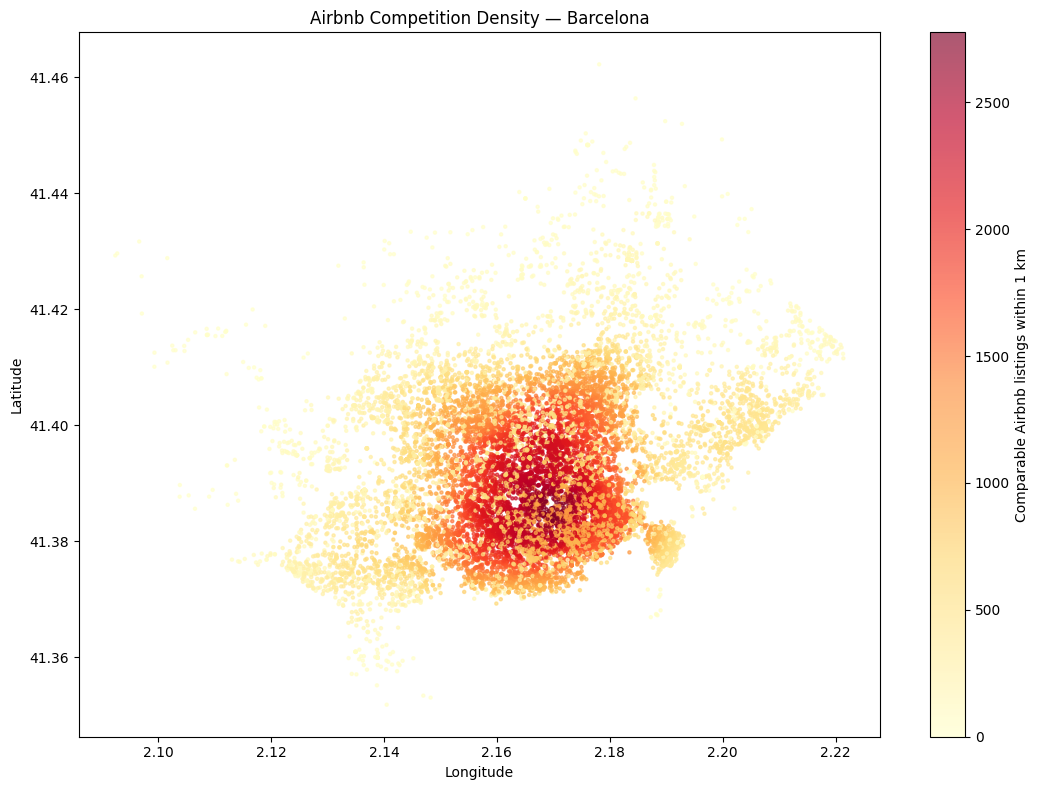

In [ ]:
#Visualization of competition feature
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 8))

scatter = plt.scatter(
    barcelona_data["longitude"],
    barcelona_data["latitude"],
    c=barcelona_data["competitors_1km"],
    cmap="YlOrRd",
    s=5,
    alpha=0.65
)

plt.colorbar(
    scatter,
    label="Comparable Airbnb listings within 1 km"
)

plt.title("Airbnb Competition Density — Barcelona")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

6. Relationships Between Variables  

In [1]:
#Nightly price vs Accommodation Capacity

accomodation = (
    listings_master
    .groupby("accommodates")["price_quote_price_per_night"]
    .median()
    .sort_values()
)

NameError: name 'listings_master' is not defined

In [ ]:
#Nightly price vs Number of Bedrooms

In [ ]:
#Nightly price vs Room Type

In [ ]:
#Nightly price vs Property Type

In [ ]:
#Price vs local competition